# SMS Spam Classification using SVM (Improved)
Dataset: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset?resource=download

**What's improved vs. the original:**
1. Light cleaning: URLs, numbers, currency and ALL-CAPS words become tokens instead of being deleted
2. Word + character TF-IDF n-grams combined
3. `class_weight='balanced'` and tuning on **F1** (not accuracy)
4. Cross-validation on the training set only (no test leakage)
5. Confusion matrix, ROC curve, error analysis and decision-threshold tuning

In [1]:
# Install (if needed)
!pip -q install wordcloud nltk scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
import re, string, nltk
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, classification_report,
confusion_matrix, ConfusionMatrixDisplay,
precision_score, recall_score, f1_score, roc_curve, auc)

nltk.download('stopwords')
nltk.download('wordnet')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


## Upload dataset (`spam.csv`) downloaded from Kaggle.

In [3]:
from google.colab import files
uploaded = files.upload()

Saving SMS.csv to SMS.csv


In [4]:
df = pd.read_csv("SMS.csv", encoding="latin-1")

df = df[['v1', 'v2']]

df.columns = ['label', 'message']

In [5]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df['label'].value_counts())

(5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


## Exploratory Data Analysis

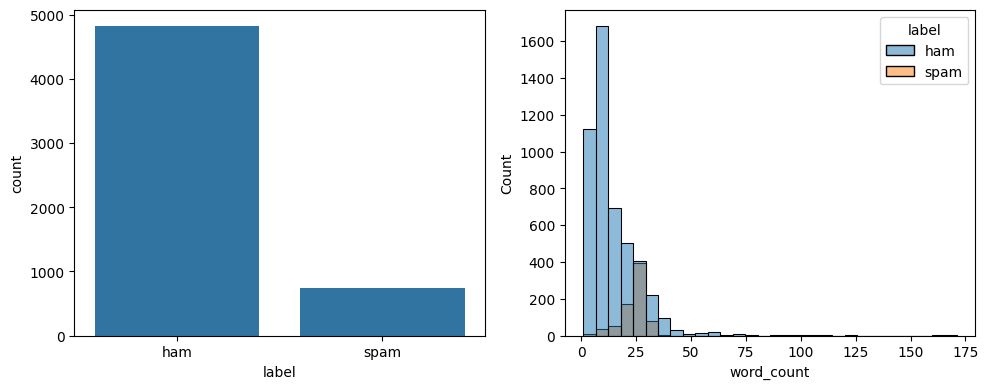

In [6]:
df['char_count'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x='label', ax=ax[0])
sns.histplot(data=df, x='word_count', hue='label', bins=30, ax=ax[1])
plt.tight_layout()
plt.show()

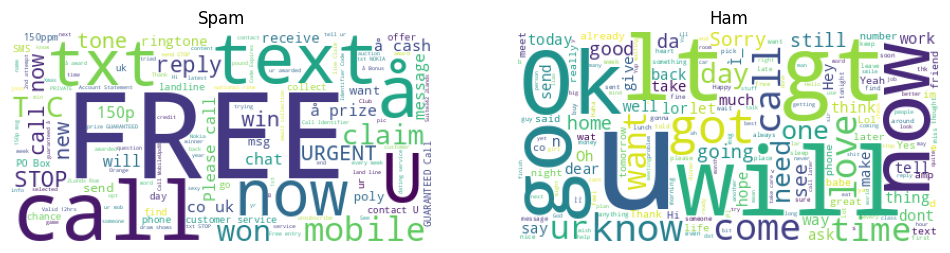

In [7]:
spam = ' '.join(df[df.label == 'spam'].message)
ham = ' '.join(df[df.label == 'ham'].message)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(WordCloud(background_color='white').generate(spam))
plt.axis('off'); plt.title("Spam")
plt.subplot(1, 2, 2)
plt.imshow(WordCloud(background_color='white').generate(ham))
plt.axis('off'); plt.title("Ham")
plt.show()

## Preprocessing
Two cleaners:
- `clean_text_old` - the original aggressive cleaning (kept only as a **baseline** for comparison)
- `clean_text` - the new light cleaning that keeps spam signals as tokens

In [8]:
# ---------- OLD cleaner (baseline for comparison) ----------
stop_words = set(stopwords.words('english'))
lemm = WordNetLemmatizer()

def clean_text_old(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'\d+', ' ', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    tokens = [lemm.lemmatize(w) for w in text.split() if w not in stop_words]
    return ' '.join(tokens)


# ---------- NEW cleaner (keeps useful spam signals) ----------
def clean_text(text):
    # Count ALL-CAPS words BEFORE lowercasing (spam loves "FREE", "WIN", "URGENT")
    caps_words = re.findall(r'\b[A-Z]{3,}\b', text)
    caps_token = ' capstoken' * min(len(caps_words), 3)

    text = text.lower()

    # Replace (not delete) key patterns with tokens
    text = re.sub(r'http\S+|www\S+', ' urltoken ', text)
    text = re.sub(r'\S+@\S+', ' emailtoken ', text)
    text = re.sub(r'\b\d{5,}\b', ' longnumtoken ', text)   # phone numbers / shortcodes
    text = re.sub(r'\d+', ' numtoken ', text)
    text = re.sub(r'[\u00a3$\u20ac]', ' currencytoken ', text)  # pound, dollar, euro

    # Keep '!' as a signal, remove other punctuation
    text = text.replace('!', ' exclamtoken ')
    text = re.sub(r'[^a-z\s]', ' ', text)

    # No stopword removal / lemmatization: the SVM handles those fine
    text = re.sub(r'\s+', ' ', text).strip()
    return text + caps_token


# Remove duplicate SMS messages
df = df.drop_duplicates().reset_index(drop=True)

# Build both versions
df['old_clean'] = df['message'].apply(clean_text_old)
df['clean_message'] = df['message'].apply(clean_text)

# ham -> 0, spam -> 1
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

df[['message', 'clean_message', 'label']].head()

,message,clean_message,label
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,0
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in numtoken a wkly comp to win fa c...,1
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,0
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...,0


## Train/Test Split

In [9]:
y = df['label']

# Split INDEXES so both the old and new text versions use the exact same split
train_idx, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=42, stratify=y
)

X_train, X_test = df.loc[train_idx, 'clean_message'], df.loc[test_idx, 'clean_message']
X_train_old, X_test_old = df.loc[train_idx, 'old_clean'], df.loc[test_idx, 'old_clean']
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print(X_train.shape, X_test.shape)
print("Spam ratio (train):", round(y_train.mean(), 3))

(4135,) (1034,)
Spam ratio (train): 0.126


## Baseline SVM (original approach)

In [10]:
baseline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('svm', LinearSVC())
])

baseline.fit(X_train_old, y_train)
pred_base = baseline.predict(X_test_old)

print("BASELINE")
print("Accuracy :", accuracy_score(y_test, pred_base))
print("Precision:", precision_score(y_test, pred_base))
print("Recall   :", recall_score(y_test, pred_base))
print("F1       :", f1_score(y_test, pred_base))

BASELINE
Accuracy : 0.9845261121856866
Precision: 0.9831932773109243
Recall   : 0.8931297709923665
F1       : 0.936


## Improved SVM Model
Word n-grams + character n-grams, sublinear TF scaling, balanced class weights.

In [11]:
features = FeatureUnion([
    ('word', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2)),
    ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                             sublinear_tf=True, min_df=2)),
])

pipeline = Pipeline([
    ('feats', features),
    ('svm', LinearSVC(class_weight='balanced', max_iter=10000))
])

pipeline.fit(X_train, y_train)
pred = pipeline.predict(X_test)

print("IMPROVED (before tuning)")
print("Accuracy :", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall   :", recall_score(y_test, pred))
print("F1       :", f1_score(y_test, pred))
print(classification_report(y_test, pred))

IMPROVED (before tuning)
Accuracy : 0.9893617021276596
Precision: 0.96875
Recall   : 0.9465648854961832
F1       : 0.9575289575289575
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       903
           1       0.97      0.95      0.96       131

    accuracy                           0.99      1034
   macro avg       0.98      0.97      0.98      1034
weighted avg       0.99      0.99      0.99      1034



## Hyperparameter Tuning (optimised for spam F1)

In [12]:
param_grid = {
    'svm__C': [0.1, 0.3, 1, 3, 10],
    'feats__char__ngram_range': [(2, 4), (2, 5)],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV F1 Score:", grid.best_score_)

Best Parameters: {'feats__char__ngram_range': (2, 5), 'svm__C': 1}
Best CV F1 Score: 0.9648208164825152


## Cross Validation (training set only - no test leakage)

In [13]:
model = grid.best_estimator_

cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')
cv_acc = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')

print("F1 per fold      :", cv_f1)
print("Mean F1          :", cv_f1.mean())
print("Mean Accuracy    :", cv_acc.mean())

F1 per fold      : [0.96       0.96078431 0.97536946 0.97142857 0.95652174]
Mean F1          : 0.9648208164825152
Mean Accuracy    : 0.9912938331318017


## Final Evaluation on the Test Set

In [14]:
pred_final = model.predict(X_test)

print("TUNED MODEL")
print("Accuracy :", accuracy_score(y_test, pred_final))
print("Precision:", precision_score(y_test, pred_final))
print("Recall   :", recall_score(y_test, pred_final))
print("F1       :", f1_score(y_test, pred_final))
print(classification_report(y_test, pred_final, target_names=['Ham', 'Spam']))

# Old vs New comparison
results = pd.DataFrame({
    'Baseline': [accuracy_score(y_test, pred_base), precision_score(y_test, pred_base),
                 recall_score(y_test, pred_base), f1_score(y_test, pred_base)],
    'Improved': [accuracy_score(y_test, pred_final), precision_score(y_test, pred_final),
                 recall_score(y_test, pred_final), f1_score(y_test, pred_final)],
}, index=['Accuracy', 'Precision', 'Recall', 'F1']).round(4)
results

TUNED MODEL
Accuracy : 0.9893617021276596
Precision: 0.96875
Recall   : 0.9465648854961832
F1       : 0.9575289575289575
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       903
        Spam       0.97      0.95      0.96       131

    accuracy                           0.99      1034
   macro avg       0.98      0.97      0.98      1034
weighted avg       0.99      0.99      0.99      1034



,Baseline,Improved
Accuracy,0.9845,0.9894
Precision,0.9832,0.9688
Recall,0.8931,0.9466
F1,0.9360,0.9575


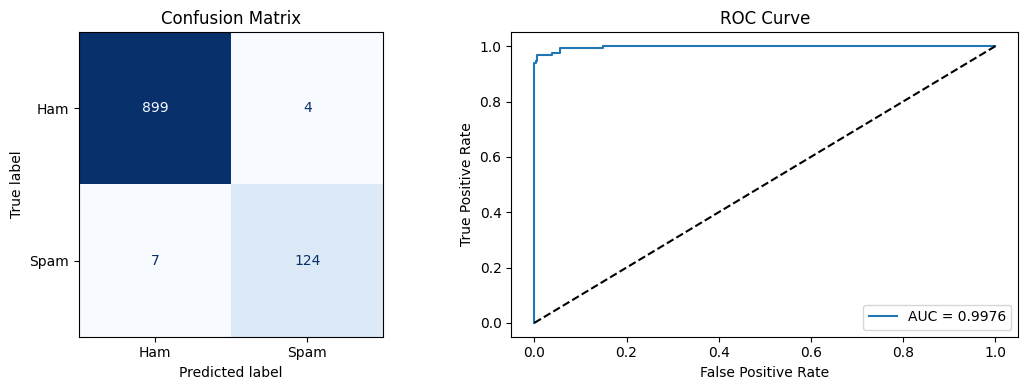

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Confusion matrix
cm = confusion_matrix(y_test, pred_final)
ConfusionMatrixDisplay(cm, display_labels=['Ham', 'Spam']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title("Confusion Matrix")

# ROC curve
scores_test = model.decision_function(X_test)
fpr, tpr, _ = roc_curve(y_test, scores_test)
ax[1].plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.4f}")
ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve"); ax[1].legend()

plt.tight_layout()
plt.show()

## Error Analysis
Look at the messages the model got wrong - this shows what to improve next.

In [16]:
errors = df.loc[X_test.index].copy()
errors['predicted'] = pred_final
errors = errors[errors['label'] != errors['predicted']]

print("Total errors:", len(errors))
print("\n--- Missed spam (False Negatives) ---")
for m in errors[errors.label == 1]['message'].head(10):
    print("-", m)

print("\n--- Ham flagged as spam (False Positives) ---")
for m in errors[errors.label == 0]['message'].head(10):
    print("-", m)

Total errors: 11

--- Missed spam (False Negatives) ---
- Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs)
- Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
- In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)
- Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!
- Latest News! Police station toilet stolen, cops have nothing to go on!
- Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
- Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner

--- Ham flagged as spam (False Positives) ---
- Host-based IDPS for linux systems.
- Your bill at 3 is 

## Decision Threshold Tuning (optional)
Default threshold is 0. Moving it trades missed spam against false alarms.

In [17]:
rows = []
for t in [-0.5, -0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3]:
    p = (scores_test > t).astype(int)
    rows.append([t, precision_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p)])

pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1']).round(4)

,threshold,precision,recall,f1
0,-0.5,0.8523,0.9695,0.9071
1,-0.3,0.9478,0.9695,0.9585
2,-0.2,0.9618,0.9618,0.9618
3,-0.1,0.9612,0.9466,0.9538
4,0.0,0.9688,0.9466,0.9575
5,0.1,0.9919,0.9389,0.9647
6,0.2,1.0000,0.9389,0.9685
7,0.3,1.0000,0.9084,0.9520


## Top Words Driving Spam / Ham Decisions

In [18]:
feat_names = model.named_steps['feats'].get_feature_names_out()
coefs = model.named_steps['svm'].coef_[0]

top_spam = np.argsort(coefs)[-15:][::-1]
top_ham = np.argsort(coefs)[:15]

print("Top SPAM features:")
print([feat_names[i] for i in top_spam])
print("\nTop HAM features:")
print([feat_names[i] for i in top_ham])

Top SPAM features:
['word__longnumtoken', 'word__urltoken', 'word__text', 'word__numtoken numtoken', 'word__arsenal', 'word__for', 'word__do do', 'word__number numtoken', 'word__your', 'char__gn', 'word__you is', 'char__ngnu', 'char__ngn', 'char__ngnum', 'char__gnumt']

Top HAM features:
['word__my', 'word__lt', 'word__at', 'char__ u ', 'char__i ', 'word__gt', 'word__me', 'word__exclamtoken exclamtoken', 'char__ i ', 'word__lt gt', 'word__am waiting', 'word__capstoken capstoken', 'word__have you', 'word__hey', 'word__up']


## Prediction Function

In [19]:
def predict_sms(text):
    cleaned = clean_text(text)
    score = model.decision_function([cleaned])[0]
    label = "Spam" if score > 0 else "Ham"
    return f"{label} (score: {score:.2f})"

print(predict_sms("Congratulations! You have won a free iPhone. Click here now."))
print(predict_sms("Hi, are we meeting tomorrow at 3 PM?"))
print(predict_sms("URGENT! Call 09061701461 now to claim your \u00a3900 prize"))
print(predict_sms("Can you send me the notes from class?"))

Spam (score: 0.14)
Ham (score: -1.28)
Spam (score: 2.17)
Ham (score: -1.06)


## Save the Model (optional)
Use this later if you want to build an app/API.

In [20]:
import joblib
joblib.dump(model, "sms_spam_svm.joblib")
# later: model = joblib.load("sms_spam_svm.joblib")

['sms_spam_svm.joblib']